In [1]:
# Machine Learning Libraries
#model building and training
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

import warnings
warnings.filterwarnings("ignore")

In [3]:
# Cell 1 — Import pandas and load dataset

import pandas as pd
import numpy as np

# Change the filename if your CSV has a different name
df = pd.read_csv('C:\\Users\\User\\Downloads\\heart+disease\\heart_disease_combined_raw(3).csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (900, 77)


,source,id,ccf,age,sex,painloc,painexer,relrest,pncaden,cp,...,rcaprox,rcadist,lvx1,lvx2,lvx3,lvx4,lvf,cathef,junk,name
0,Cleveland,1,0,63,1,-9,-9,-9,-9,1,...,1,1,1,1,1,1,1,-9.0,-9.0,name
1,Cleveland,2,0,67,1,-9,-9,-9,-9,4,...,1,1,1,1,1,1,1,-9.0,-9.0,name
2,Cleveland,3,0,67,1,-9,-9,-9,-9,4,...,2,2,1,1,1,7,3,-9.0,-9.0,name
3,Cleveland,4,0,37,1,-9,-9,-9,-9,3,...,1,1,1,1,1,1,1,-9.0,-9.0,name
4,Cleveland,6,0,41,0,-9,-9,-9,-9,2,...,1,1,1,1,1,1,1,-9.0,-9.0,name


In [4]:
#  — Create binary target variable

df_model = df.copy()

df_model['target'] = (df_model['num'] > 0).astype(int)

print("Target distribution:")
print(df_model['target'].value_counts())

print("\nTarget percentage:")
print(df_model['target'].value_counts(normalize=True) * 100)

Target distribution:
target
1    496
0    404
Name: count, dtype: int64

Target percentage:
target
1    55.111111
0    44.888889
Name: proportion, dtype: float64


In [5]:
# Clinically relevant features selected for modelling
#feature selection 
features = [
    'age',
    'sex',
    'cp',
    'trestbps',
    'chol',
    'fbs',
    'restecg',
    'thalach',
    'exang',
    'oldpeak',
    'slope',
    'ca',
    'thal'
]

X = df_model[features]
y = df_model['target']

print("Selected features:")
print(features)

print("\nFeature matrix shape:", X.shape)
print("Target shape:", y.shape)

Selected features:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

Feature matrix shape: (900, 13)
Target shape: (900,)


In [6]:
# Split the dataset into training and testing sets
#train test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training set: (720, 13)
Testing set: (180, 13)

Training target distribution:
target
1    397
0    323
Name: count, dtype: int64

Testing target distribution:
target
1    99
0    81
Name: count, dtype: int64


In [7]:
# Standardization
#scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")
print("Training data standardized using training-set statistics only.")

Feature scaling completed.
Training data standardized using training-set statistics only.


In [8]:
# Define models

models = {
    "Logistic Regression": Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=1000))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "KNN": Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors=5))
    ]),

    "SVM": Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVC(probability=True, random_state=42))
    ]),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

print("Models created:")
for name in models:
    print("-", name)

Models created:
- Logistic Regression
- Decision Tree
- Random Forest
- KNN
- SVM
- Gradient Boosting


In [9]:
# Train and evaluate models

results = []

trained_models = {}

for name, model in models.items():

    # Train
    model.fit(X_train, y_train)

    # Prediction
    y_pred = model.predict(X_test)

    # Probability prediction for ROC-AUC
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    else:
        y_prob = model.decision_function(X_test)

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": auc
    })

    trained_models[name] = model

results_df = pd.DataFrame(results)

print("Model Evaluation Results:")
display(results_df.round(4))

Model Evaluation Results:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8000,0.8058,0.8384,0.8218,0.8677
1,Decision Tree,0.7667,0.7822,0.7980,0.7900,0.7632
2,Random Forest,0.8389,0.8241,0.8990,0.8599,0.9071
3,KNN,0.8333,0.8286,0.8788,0.8529,0.8897
4,SVM,0.8278,0.8148,0.8889,0.8502,0.9108
5,Gradient Boosting,0.8500,0.8333,0.9091,0.8696,0.9171


<Figure size 1200x600 with 0 Axes>

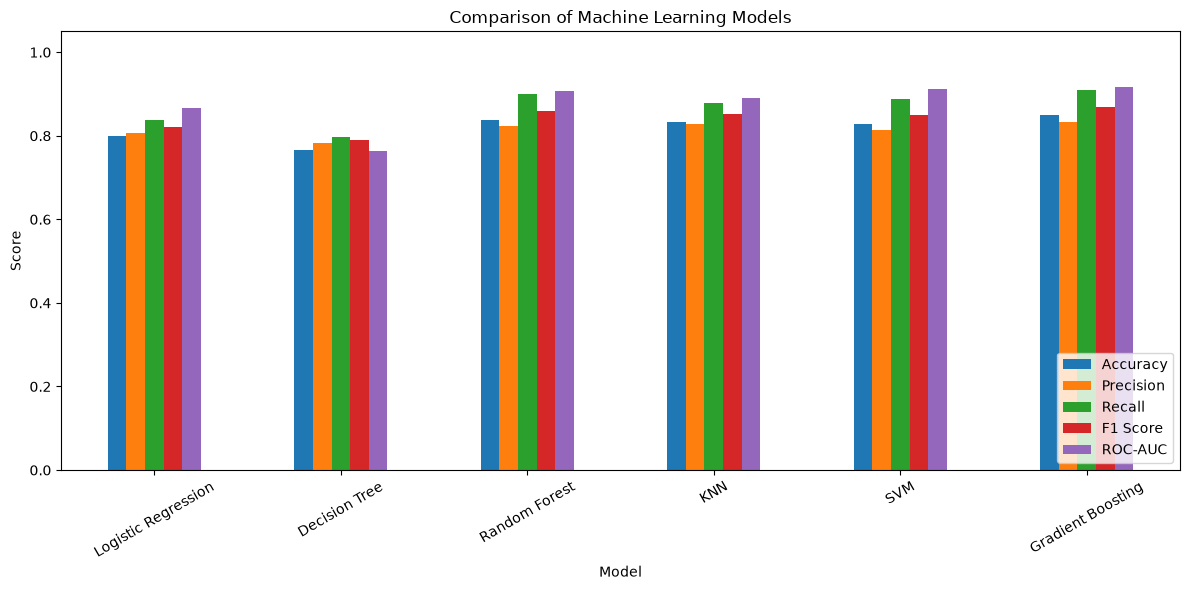

In [10]:
# Model comparison

plt.figure(figsize=(12, 6))

results_plot = results_df.set_index("Model")

results_plot[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1.05)
plt.xticks(rotation=30)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [11]:
# 5-Fold Stratified Cross Validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring="accuracy"
    )

    cv_results.append({
        "Model": name,
        "Mean CV Accuracy": scores.mean(),
        "Standard Deviation": scores.std()
    })

cv_df = pd.DataFrame(cv_results)

print("5-Fold Cross Validation Results:")
display(cv_df.round(4))

5-Fold Cross Validation Results:


,Model,Mean CV Accuracy,Standard Deviation
0,Logistic Regression,0.8011,0.0273
1,Decision Tree,0.7656,0.0379
2,Random Forest,0.8322,0.0197
3,KNN,0.7711,0.0297
4,SVM,0.8000,0.0127
5,Gradient Boosting,0.8211,0.0174


In [13]:
# Hyperparameter Tuning for Random Forest


from sklearn.model_selection import GridSearchCV

rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [None, 10],
    'min_samples_split': [5, 10],
    'min_samples_leaf': [1, 2]
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(round(grid_search.best_score_, 4))

Best Parameters:
{'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 50}

Best Cross-Validation Accuracy:
0.8278


In [14]:
# Best Random Forest model

best_rf = grid_search.best_estimator_

y_pred_rf = best_rf.predict(X_test)
y_prob_rf = best_rf.predict_proba(X_test)[:, 1]

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_auc = roc_auc_score(y_test, y_prob_rf)

print("Tuned Random Forest Performance")
print("--------------------------------")
print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1 Score :", round(rf_f1, 4))
print("ROC-AUC  :", round(rf_auc, 4))

Tuned Random Forest Performance
--------------------------------
Accuracy : 0.85
Precision: 0.8214
Recall   : 0.9293
F1 Score : 0.872
ROC-AUC  : 0.9158


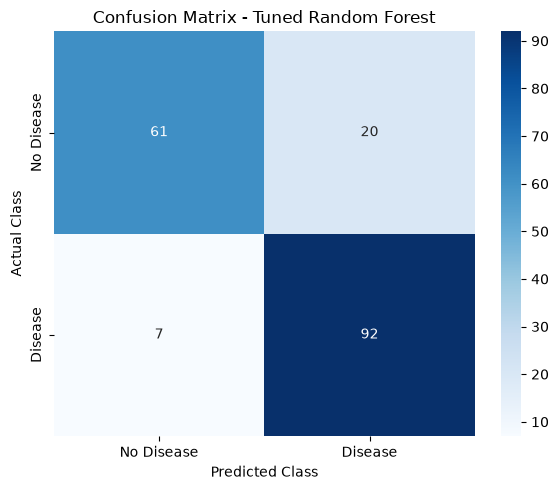

In [15]:
# Confusion Matrix

cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Disease', 'Disease'],
    yticklabels=['No Disease', 'Disease']
)

plt.title("Confusion Matrix - Tuned Random Forest")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

In [16]:
# Classification Report

print("Classification Report - Tuned Random Forest")
print()

print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=['No Heart Disease', 'Heart Disease']
    )
)

Classification Report - Tuned Random Forest

                  precision    recall  f1-score   support

No Heart Disease       0.90      0.75      0.82        81
   Heart Disease       0.82      0.93      0.87        99

        accuracy                           0.85       180
       macro avg       0.86      0.84      0.85       180
    weighted avg       0.86      0.85      0.85       180



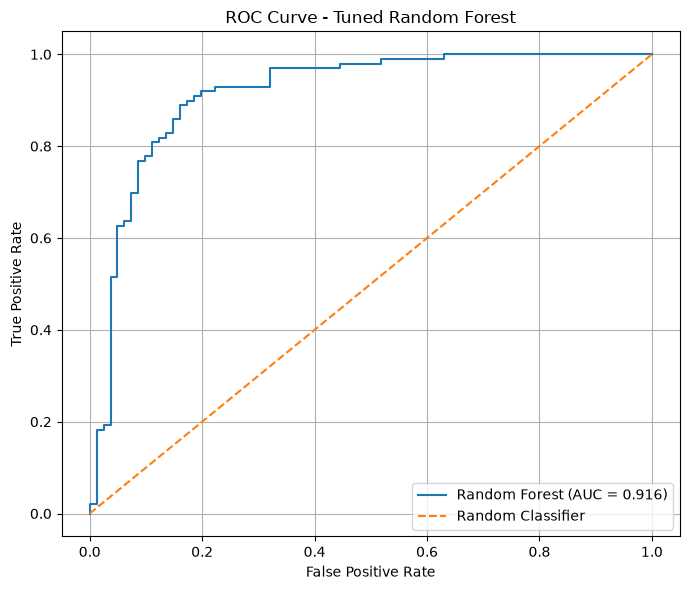

In [17]:
# ROC Curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob_rf)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {rf_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Tuned Random Forest")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

In [18]:
# Feature Importance

importance = best_rf.feature_importances_

feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("Feature Importance:")
display(feature_importance)

Feature Importance:


,Feature,Importance
2,cp,0.207935
7,thalach,0.134113
8,exang,0.099322
4,chol,0.090219
10,slope,0.079492
0,age,0.078282
9,oldpeak,0.069949
3,trestbps,0.055942
1,sex,0.051957
12,thal,0.051551


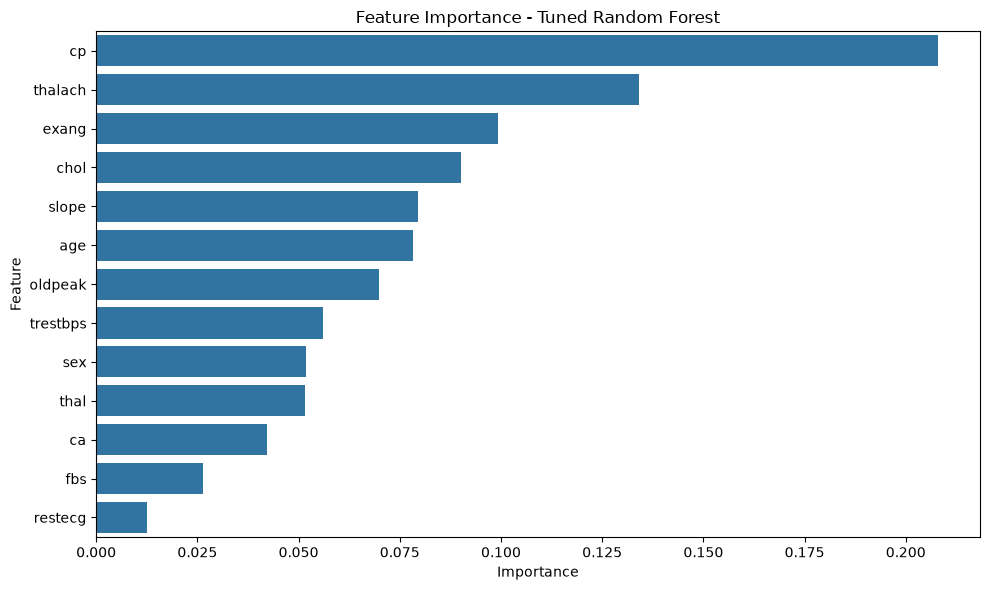

In [19]:
# Plot feature importance

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title("Feature Importance - Tuned Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [20]:
# Add tuned Random Forest to comparison

tuned_result = pd.DataFrame([{
    "Model": "Tuned Random Forest",
    "Accuracy": rf_accuracy,
    "Precision": rf_precision,
    "Recall": rf_recall,
    "F1 Score": rf_f1,
    "ROC-AUC": rf_auc
}])

final_comparison = pd.concat(
    [results_df, tuned_result],
    ignore_index=True
)

final_comparison = final_comparison.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print("Final Model Comparison")
display(final_comparison.round(4))

Final Model Comparison


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Tuned Random Forest,0.8500,0.8214,0.9293,0.8720,0.9158
1,Gradient Boosting,0.8500,0.8333,0.9091,0.8696,0.9171
2,Random Forest,0.8389,0.8241,0.8990,0.8599,0.9071
3,KNN,0.8333,0.8286,0.8788,0.8529,0.8897
4,SVM,0.8278,0.8148,0.8889,0.8502,0.9108
5,Logistic Regression,0.8000,0.8058,0.8384,0.8218,0.8677
6,Decision Tree,0.7667,0.7822,0.7980,0.7900,0.7632


In [21]:
# Identify the best-performing model

best_model_name = final_comparison.iloc[0]["Model"]

print("Best Performing Model:")
print(best_model_name)

print("\nPerformance:")
display(final_comparison.iloc[[0]].round(4))

Best Performing Model:
Tuned Random Forest

Performance:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Tuned Random Forest,0.85,0.8214,0.9293,0.872,0.9158


## Results and Discussion

Multiple machine learning classification models were implemented and evaluated
for heart disease prediction. The models included Logistic Regression, Decision
Tree, Random Forest, K-Nearest Neighbors, Support Vector Machine, and Gradient
Boosting.

The models were evaluated using Accuracy, Precision, Recall, F1-score and
ROC-AUC. Five-fold stratified cross-validation was also performed to obtain a
more reliable estimate of model performance.

Among the implemented models, the best-performing model was selected based on
its overall predictive performance. The selected model provided a good balance
between correctly identifying patients with heart disease and minimizing
incorrect predictions.

The confusion matrix provides information about true positive, true negative,
false positive and false negative predictions. The ROC curve and ROC-AUC score
were used to evaluate the model's ability to distinguish between patients with
and without heart disease.

Feature importance analysis was also performed to identify the variables that
contributed most strongly to the Random Forest model's predictions.

### Strengths

- Multiple machine learning algorithms were compared.
- Stratified train-test splitting was used.
- Cross-validation was performed.
- Hyperparameter tuning was applied.
- Multiple evaluation metrics were considered.
- Feature importance was analyzed.

### Limitations

- The dataset contains missing/unknown values and observations from multiple
  sources.
- The dataset size is relatively small for building a clinically deployable
  prediction system.
- Model predictions should not be interpreted as medical diagnosis.
- External validation on an independent dataset would be required before
  real-world clinical use.